# Retinal Recognition – Evaluation 
Data loading, dataset checks and evaluation for the retinal vessel recognition system.
Dataset: RIDB (Akram et al., 2020), 100 fundus images of 20 people (5 per person).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ridb_loader import load_ridb, check_same_eye

Imports NumPy and Matplotlib, plus the RIDB loader and the same-eye check from `ridb_loader.py`.

### 2. Load RIDB
Filenames follow `IM00000X_Y.jpg`, where X is the image number and Y is the person.


In [2]:
ridb = load_ridb()
print(len(ridb), "people,", sum(len(v) for v in ridb.values()), "images")
for p, imgs in ridb.items():
    assert len(imgs) == 5, f"Person {p} has {len(imgs)} images"

20 people, 100 images


Loads every image from `Data/RIDB`, reads the person and image number from each filename, and groups the images by person. The assert stops the notebook if any person does not have exactly 5 images.

### 3. Same-Eye Check
Left and right eyes have the optic disc on opposite sides. If all 5 images of a person have the disc on the same side, they are the same eye.

Person  1: ['right', 'right', 'right', 'right', 'right']


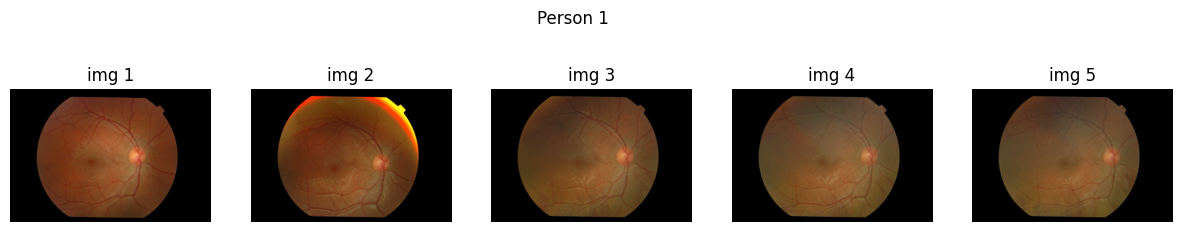

Person  2: ['left', 'left', 'left', 'left', 'left']


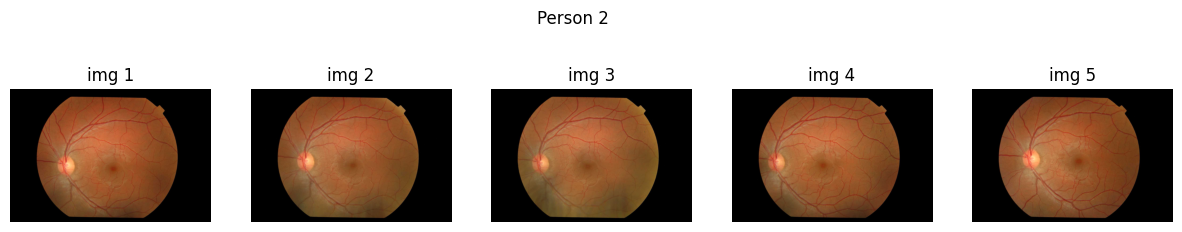

Person  3: ['right', 'right', 'right', 'right', 'right']


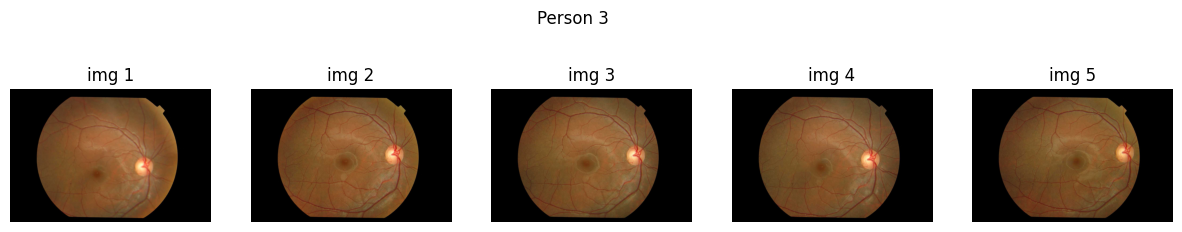

Person  4: ['left', 'left', 'left', 'left', 'left']


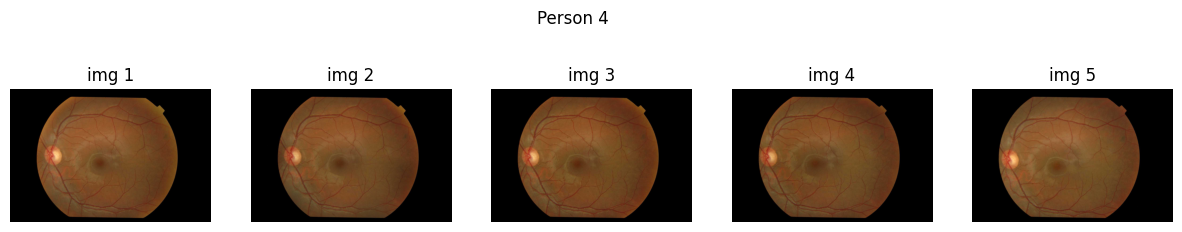

Person  5: ['right', 'right', 'right', 'right', 'right']


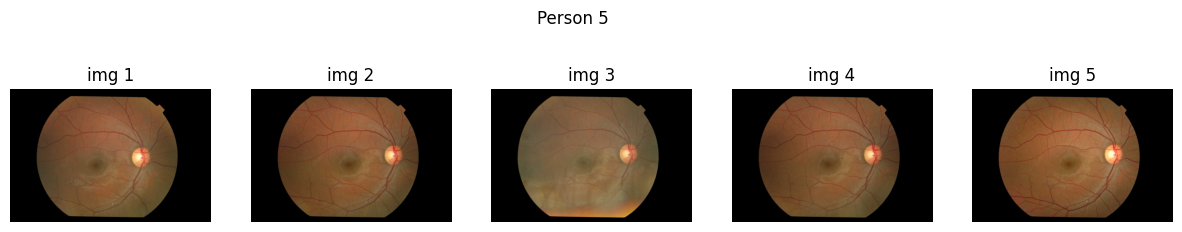

Person  6: ['left', 'left', 'left', 'left', 'left']


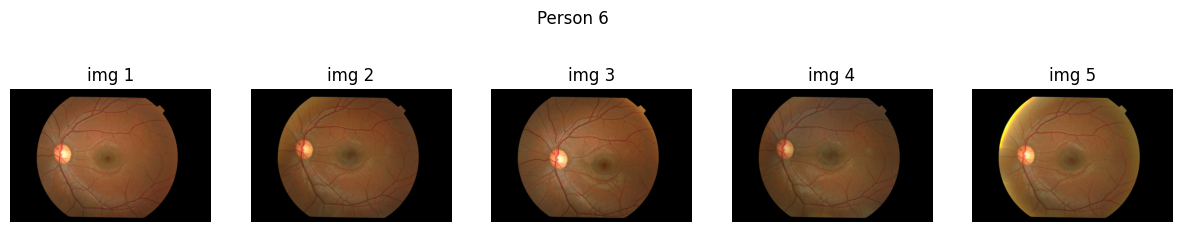

Person  7: ['right', 'right', 'right', 'right', 'right']


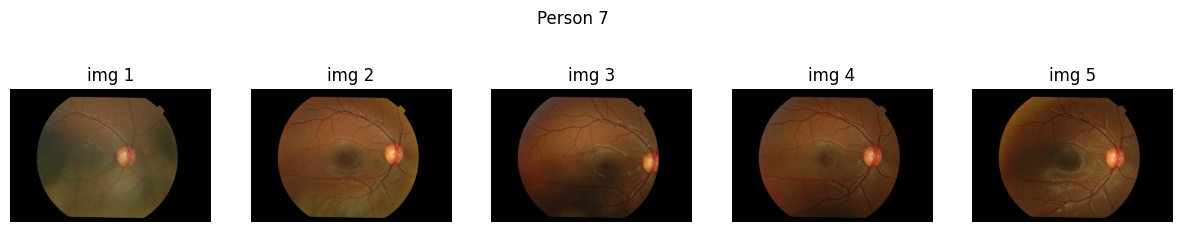

Person  8: ['left', 'left', 'left', 'left', 'left']


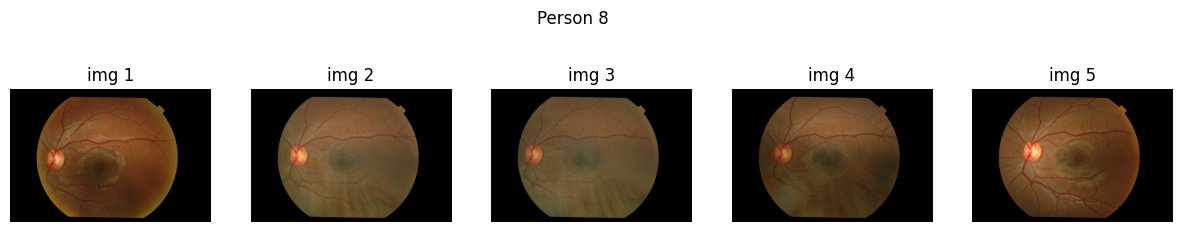

Person  9: ['right', 'right', 'right', 'right', 'right']


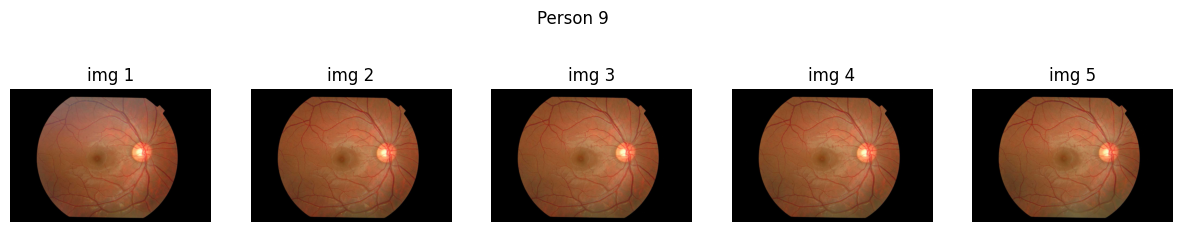

Person 10: ['left', 'left', 'left', 'left', 'left']


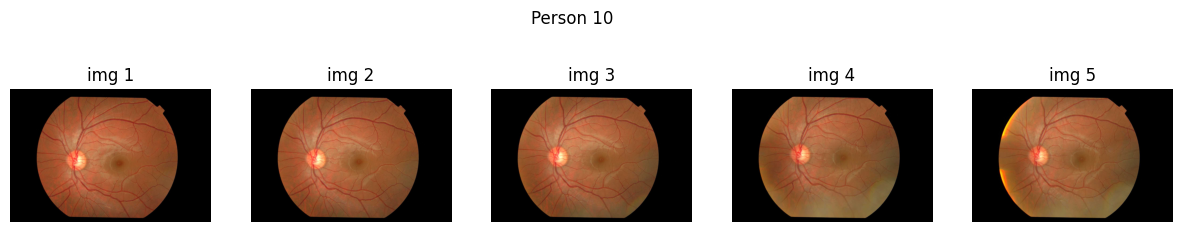

Person 11: ['right', 'right', 'right', 'right', 'right']


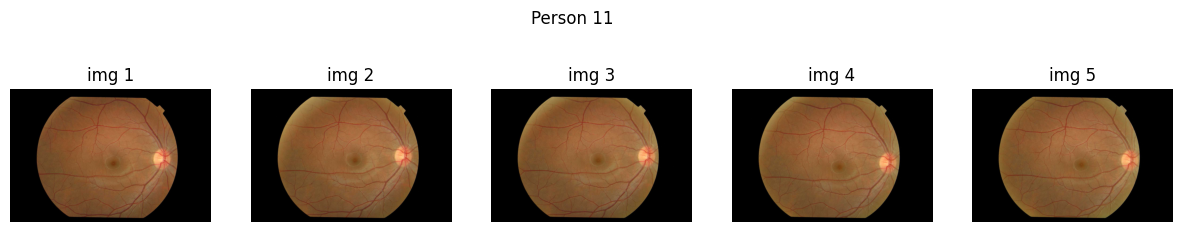

Person 12: ['left', 'left', 'left', 'left', 'left']


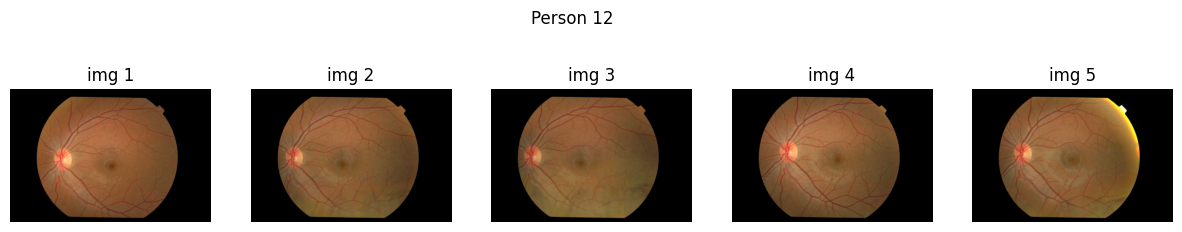

Person 13: ['right', 'right', 'right', 'right', 'right']


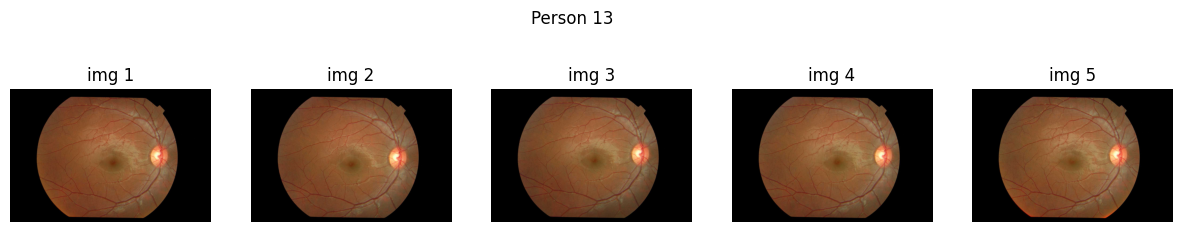

Person 14: ['left', 'left', 'left', 'left', 'left']


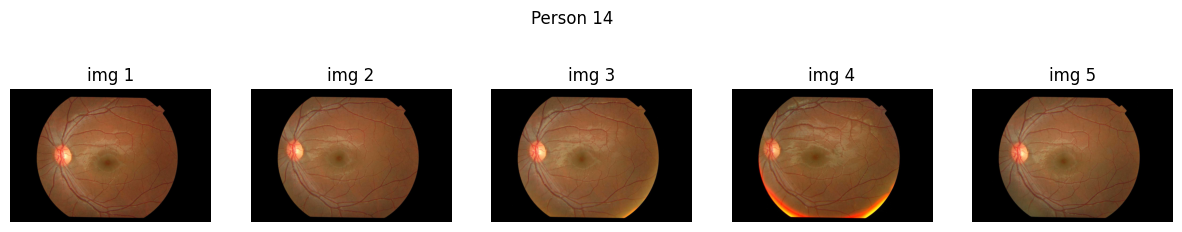

Person 15: ['right', 'right', 'right', 'right', 'right']


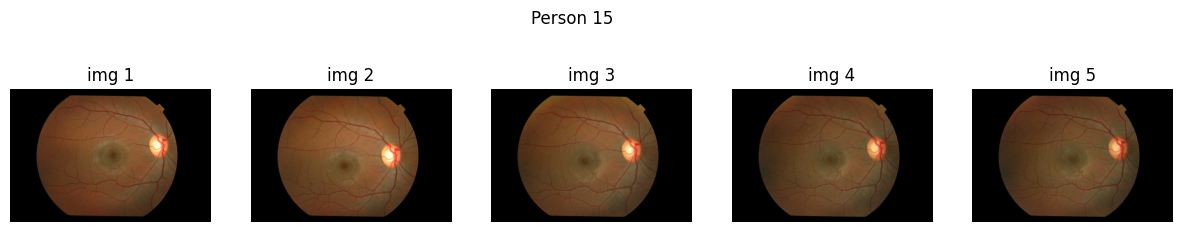

Person 16: ['left', 'left', 'left', 'left', 'left']


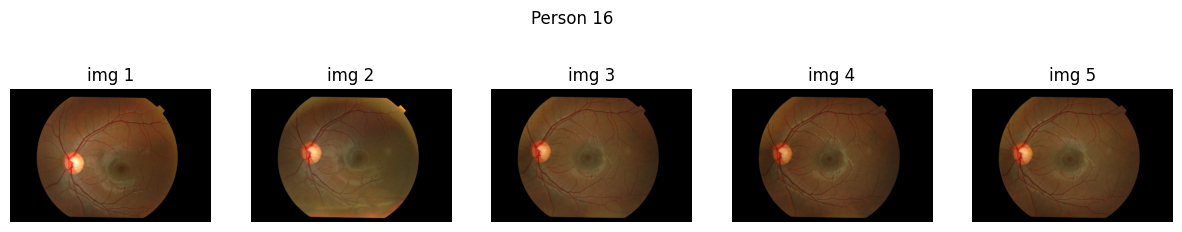

Person 17: ['right', 'right', 'right', 'right', 'right']


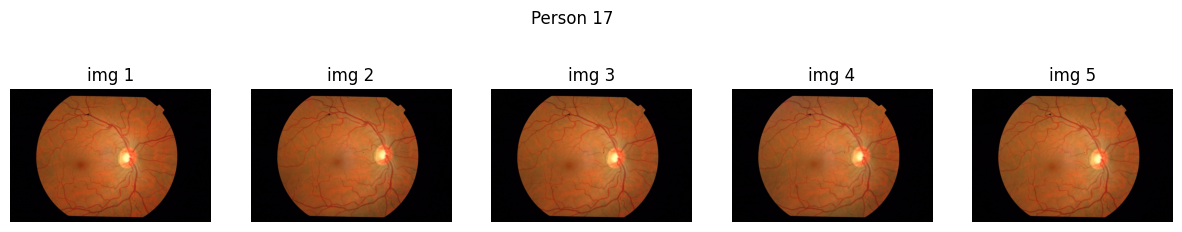

Person 18: ['left', 'left', 'left', 'left', 'left']


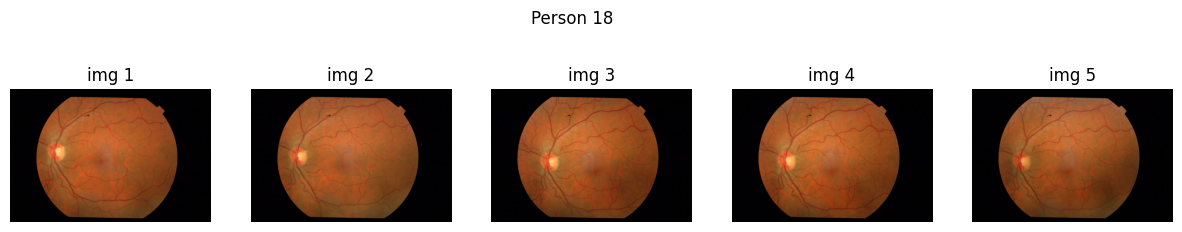

Person 19: ['right', 'right', 'right', 'right', 'right']


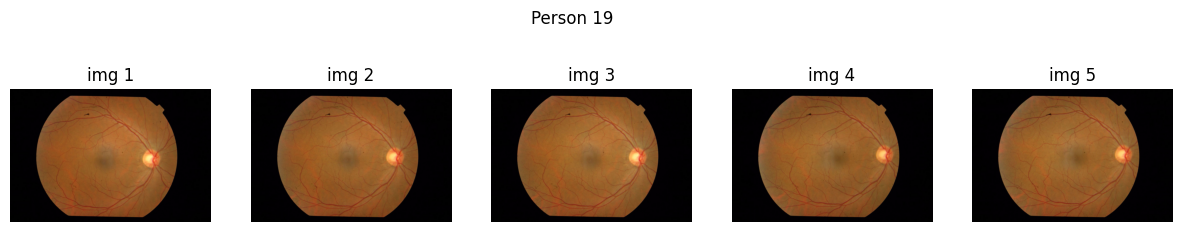

Person 20: ['left', 'left', 'left', 'left', 'left']


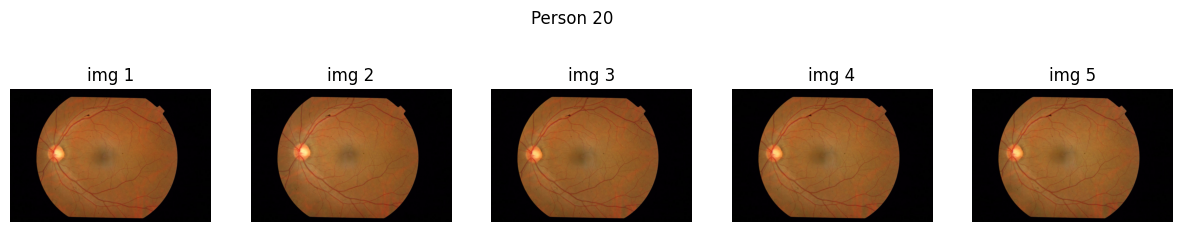

Flagged: none


In [3]:
flagged = check_same_eye(ridb, show=True)
print("Flagged:", flagged if flagged else "none")

   ### 4. Eye Side per Person

In [4]:
from ridb_loader import disc_side
sides = {p: disc_side(imgs[0][1]) for p, imgs in ridb.items()}
print("Left eyes:", [p for p, s in sides.items() if s == "left"])
print("Right eyes:", [p for p, s in sides.items() if s == "right"])

Left eyes: [10, 12, 14, 16, 18, 2, 20, 4, 6, 8]
Right eyes: [1, 11, 13, 15, 17, 19, 3, 5, 7, 9]


### 5. Enrol / Probe / Impostor Split

In [5]:
from split import make_split

enrol, probes, impostors = make_split(ridb, n_enrol_people=15, seed=42)
print("Enrolled people:", sorted(enrol))
print("Unknown people: ", sorted({p for p, _ in impostors}))
print(f"{len(enrol)} templates, {len(probes)} probe images, {len(impostors)} impostor images")

Enrolled people: [2, 3, 5, 6, 7, 10, 11, 12, 13, 14, 15, 16, 18, 19, 20]
Unknown people:  [1, 4, 8, 9, 17]
15 templates, 60 probe images, 25 impostor images


15 people are enrolled using their first image. Their other 4 images are the probes (60 genuine attempts). The remaining 5 people are never enrolled, so all 25 of their images act as impostors and test "unknown" rejection. The fixed seed makes the split the same on every run.

### 6. Test FAR / FRR / EER with Dummy Scores

Overlap:  EER = 0.0211 (expected ~0.0228), threshold = 0.603 (expected ~0.6)
Separate: EER = 0.0000 (expected 0)
Same:     EER = 0.4984 (expected ~0.5)


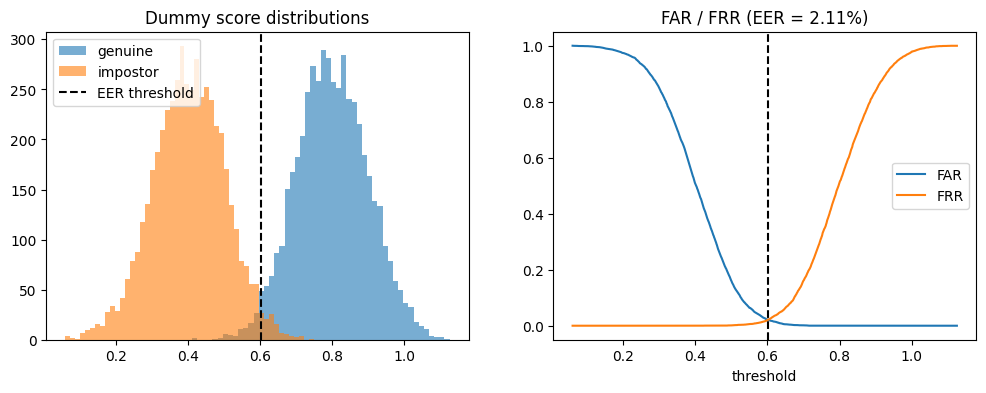

In [6]:
from metrics import eer

rng = np.random.default_rng(0)

# Case 1: overlapping normals, means 0.8 vs 0.4, sd 0.1 -> theoretical EER ≈ 2.28% at t ≈ 0.6
g = rng.normal(0.8, 0.1, 5000)
i = rng.normal(0.4, 0.1, 5000)
e, t, ts, far, frr = eer(g, i)
print(f"Overlap:  EER = {e:.4f} (expected ~0.0228), threshold = {t:.3f} (expected ~0.6)")
assert abs(e - 0.0228) < 0.01 and abs(t - 0.6) < 0.03

# Case 2: perfect separation -> EER = 0
e2, *_ = eer(rng.uniform(0.7, 1.0, 500), rng.uniform(0.0, 0.3, 500))
print(f"Separate: EER = {e2:.4f} (expected 0)")
assert e2 == 0

# Case 3: identical distributions -> EER ≈ 0.5
e3, *_ = eer(rng.normal(0.5, 0.1, 5000), rng.normal(0.5, 0.1, 5000))
print(f"Same:     EER = {e3:.4f} (expected ~0.5)")
assert abs(e3 - 0.5) < 0.05

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.hist(g, bins=50, alpha=0.6, label="genuine")
a1.hist(i, bins=50, alpha=0.6, label="impostor")
a1.axvline(t, color="k", ls="--", label="EER threshold")
a1.set_title("Dummy score distributions"); a1.legend()
a2.plot(ts, far, label="FAR"); a2.plot(ts, frr, label="FRR")
a2.axvline(t, color="k", ls="--")
a2.set_xlabel("threshold"); a2.set_title(f"FAR / FRR (EER = {e:.2%})"); a2.legend()
plt.show()

Checks the metrics code against cases with known answers before using real scores. Two normal distributions 4 standard deviations apart should give an EER of about 2.28% at the midpoint 0.6. Perfectly separated scores should give 0, and identical distributions about 0.5. All three asserts pass, so the FAR, FRR and EER code is correct.

### 7. Enrolment and Template Storage

In [7]:
from enrolment import enrol_all, load_templates, dummy_features, TEMPLATE_PATH

templates = enrol_all(enrol, extract_features=dummy_features)
loaded = load_templates()

assert loaded.keys() == templates.keys()
assert all(np.array_equal(loaded[p], templates[p]) for p in templates)
print(f"Saved and reloaded {len(loaded)} templates from {TEMPLATE_PATH.name}")
print("Template length:", len(next(iter(loaded.values()))))

Saved and reloaded 15 templates from templates.pkl
Template length: 4096


Extracts a template from each enrolled person's image, saves them all to `Templates/templates.pkl`, then reloads the file and checks it matches. `dummy_features` (a 64×64 green-channel thumbnail) is a placeholder; Person B's feature extractor will be passed in as `extract_features` instead.

### 8. End-to-End Test with Dummy Features

60 genuine, 840 zero-effort, 375 unknown comparisons
Dummy-feature EER = 29.61% at threshold 0.941


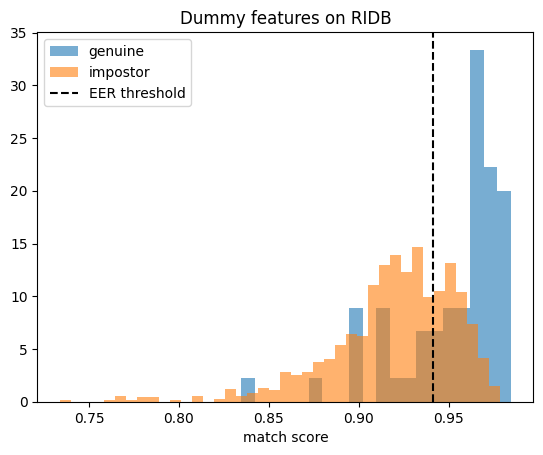

In [8]:
from scoring import score_all

genuine, zero_effort, unknown = score_all(templates, probes, impostors, dummy_features)
impostor_all = np.concatenate([zero_effort, unknown])
print(f"{len(genuine)} genuine, {len(zero_effort)} zero-effort, {len(unknown)} unknown comparisons")

e, t, ts, far, frr = eer(genuine, impostor_all)
print(f"Dummy-feature EER = {e:.2%} at threshold {t:.3f}")

plt.hist(genuine, bins=20, alpha=0.6, density=True, label="genuine")
plt.hist(impostor_all, bins=40, alpha=0.6, density=True, label="impostor")
plt.axvline(t, color="k", ls="--", label="EER threshold")
plt.xlabel("match score"); plt.legend(); plt.title("Dummy features on RIDB")
plt.show()

Runs the whole evaluation pipeline on real RIDB images. It gives 60 genuine comparisons, 840 against other enrolled people and 375 from unknown people. The dummy features are just thumbnails, so the EER is only a baseline. The pipeline is ready, and once Person B's features and matcher are plugged in the same cell gives the real result.